# CSCI 3003 - Data Visualization
## Lab 6A: Relationships and Regression with statsmodels
**Name:** Steve Tatstiguia  
**Date:** 2026-09-24  
**Version:** Student notebook

## Learning objectives
By the end, you should be able to:
- Design and interpret a scatterplot of two quantitative variables.
- Fit a simple linear regression with the statsmodels formula interface.
- Interpret slope, intercept, confidence interval, p-value, and R-squared.
- Distinguish mean confidence intervals from individual prediction intervals.
- Construct residual plots and identify model limitations.
- Describe association without claiming causation.

## I. Setup and prepare the data
The working directory is already `01-labs/`. The formula `body_mass_g ~ flipper_length_mm` means model body mass using flipper length.

If needed, install `statsmodels`:

```powershell
pip install statsmodels
```

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

In [2]:
penguin_file=Path("penguins.csv")
print(Path.cwd(), penguin_file.exists())
penguins=pd.read_csv(penguin_file)
penguins.head()

c:\Users\steve\OneDrive\Documents\CSCI-3003-Data-Visualization\01-labs True


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


**Question 1:** What does one row represent? Identify the response, explanatory variable, and their units.

**Answer:** One row represents one penguin. The response variable is body_mass_g, measured in grams, and the explanatory variable is flipper_length_mm, measured in millimeters.

**Question 2:** How many complete rows remain, and what are the observed ranges?

**Answer:** There are 342 complete rows. Flipper length ranges from about 172 mm to 231 mm, and body mass ranges from about 2700 g to 6300 g.

## II. Visualize before modeling
One point represents one penguin. Transparency helps reveal overlap. Describe direction, form, strength, and unusual features before fitting.

In [3]:
relationship_data=(penguins
 .loc[:,["flipper_length_mm","body_mass_g","species"]]
 .dropna(subset=["flipper_length_mm","body_mass_g"]))
relationship_data.describe(include="all")

,flipper_length_mm,body_mass_g,species
count,342.000000,342.000000,342
unique,NaN,NaN,3
top,NaN,NaN,Adelie
freq,NaN,NaN,151
mean,200.915205,4201.754386,NaN
std,14.061714,801.954536,NaN
min,172.000000,2700.000000,NaN
25%,190.000000,3550.000000,NaN
50%,197.000000,4050.000000,NaN
75%,213.000000,4750.000000,NaN


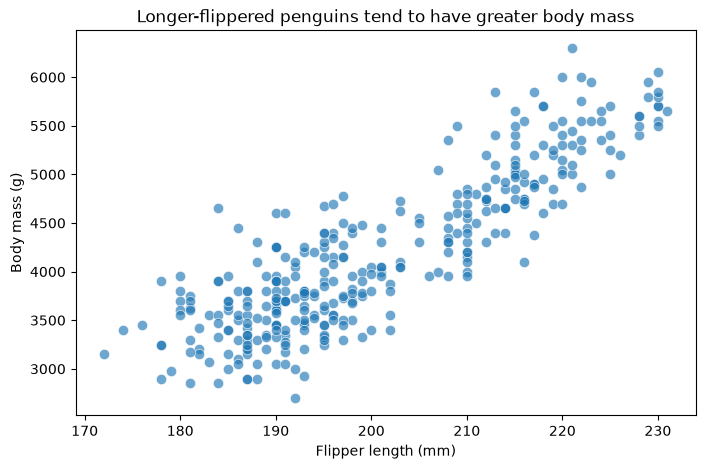

In [4]:
fig,ax=plt.subplots(figsize=(8,5))
sns.scatterplot(
    data=relationship_data,
    x="flipper_length_mm",
    y="body_mass_g",
    alpha=.65,
    s=55,
    ax=ax
)
ax.set(title="Longer-flippered penguins tend to have greater body mass",xlabel="Flipper length (mm)",ylabel="Body mass (g)")
plt.show()

**Question 3:** Describe the relationship. Why would a causal claim exceed this observational evidence?

**Answer:** There is a strong positive relationship between flipper length and body mass. Penguins with longer flippers tend to weigh more. This does not prove cause and effect because other factors, like species, could influence both variables.

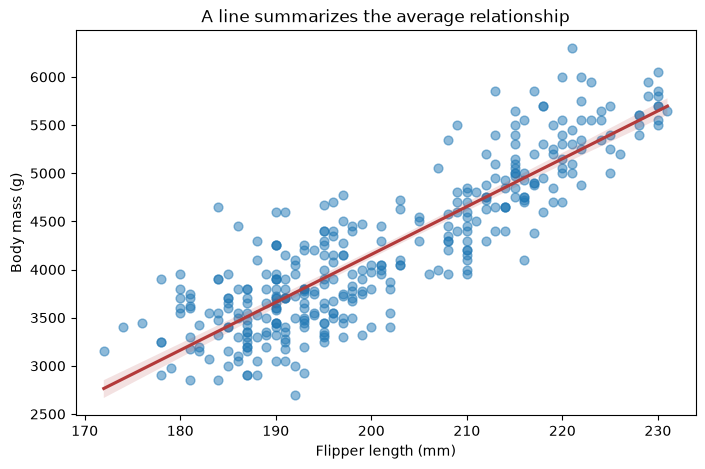

In [5]:
fig,ax=plt.subplots(figsize=(8,5))
sns.regplot(
    data=relationship_data,
    x="flipper_length_mm",
    y="body_mass_g",
    # kws = keyword arguments (kwargs)
    scatter_kws={"alpha":.5,"s":40}, # styling options for points
    line_kws={"color":"#B33A3A"},  # styling options for regression line
    ax=ax
)
ax.set(
    title="A line summarizes the average relationship",
    xlabel="Flipper length (mm)",
    ylabel="Body mass (g)"
)
plt.show()

**Question 4:** What does the line summarize? Why is the shaded mean-confidence band not a range containing 95% of individual penguins?

**Answer:** The line shows the estimated average body mass for each flipper length. The shaded band shows uncertainty around that average, not where 95% of individual penguins are expected to fall.


**Hint:**
The line = estimated average body mass for a given flipper length.  
The shaded band = uncertainty in that average estimate.

## III. Fit and interpret an OLS model
Ordinary least squares chooses coefficients that minimize squared residuals. A residual is observed minus fitted.

In [6]:
mass_model=smf.ols(
    "body_mass_g ~ flipper_length_mm",
    data=relationship_data
).fit()
mass_model.params

Intercept           -5780.831358
flipper_length_mm      49.685566
dtype: float64

In [7]:
pd.DataFrame({
    "estimate":mass_model.params,
    "standard_error":mass_model.bse,
    "p_value":mass_model.pvalues,
    "ci_lower":mass_model.conf_int()[0],
    "ci_upper":mass_model.conf_int()[1]
})

,estimate,standard_error,p_value,ci_lower,ci_upper
Intercept,-5780.831358,305.814504,5.587301e-55,-6382.358008,-5179.304708
flipper_length_mm,49.685566,1.518404,4.370681e-107,46.698918,52.672215


In [8]:
"R-squared", mass_model.rsquared

('R-squared', np.float64(0.7589925193571178))

**Question 5:** Write the fitted equation for this model. Interpret the slope in grams per millimeter. Why is the intercept not substantively useful?

**Answer:** The fitted equation is: Body mass = -5780.8 + 49.69(flipper length)
For every 1 mm increase in flipper length, body mass increases by about 49.7 g on average. The intercept is not very useful because a flipper length of 0 mm is not realistic

**Question 6:** Interpret the slope confidence interval, p-value, and R-squared.

**Answer:** The slope confidence interval is about 46.7 to 52.7 g/mm, so the relationship is clearly positive. The p-value is extremely small, which suggests the relationship is statistically significant. The R^2 is about 0.759, meaning flipper length explains about 76% of the variation in body mass

## Check your work: model quantities
Use this only after Questions 5-6.
- The slope is positive and measured in grams per additional millimeter.
- Its interval remains above zero.
- R-squared describes variation associated with this fitted line—not accuracy or causation.

## IV. Visualize uncertainty
`mean_ci_*` describes uncertainty about the mean response. `obs_ci_*` describes uncertainty for one individual response and is wider.

In [9]:
grid = pd.DataFrame(
    {
        "flipper_length_mm": np.linspace(
            relationship_data.flipper_length_mm.min(),
            relationship_data.flipper_length_mm.max(),
            100,
        )
    }
)
summary = mass_model.get_prediction(grid).summary_frame()
plot_data = pd.concat(
    [grid.reset_index(drop=True), summary.reset_index(drop=True)], axis=1
)
plot_data.head()

,flipper_length_mm,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,172.000000,2765.086064,48.807714,2669.082962,2861.089166,1983.634876,3546.537251
1,172.595960,2794.696654,47.995333,2700.291478,2889.101830,2013.440166,3575.953142
2,173.191919,2824.307244,47.186319,2731.493371,2917.121117,2043.241448,3605.373040
3,173.787879,2853.917834,46.380849,2762.688293,2945.147375,2073.038719,3634.796949
4,174.383838,2883.528424,45.579111,2793.875875,2973.180973,2102.831977,3664.224871


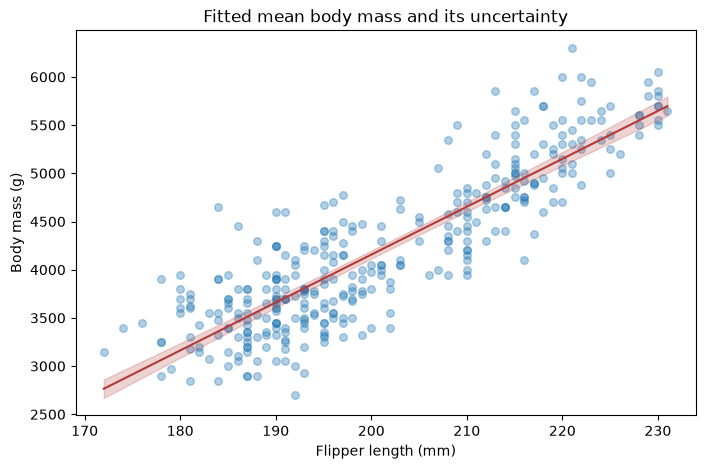

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    relationship_data.flipper_length_mm, relationship_data.body_mass_g, alpha=0.35, s=30
)
ax.plot(plot_data.flipper_length_mm, plot_data["mean"], color="#B33A3A")
ax.fill_between(
    plot_data.flipper_length_mm,
    plot_data.mean_ci_lower,
    plot_data.mean_ci_upper,
    color="#B33A3A",
    alpha=0.22,
)
ax.set(
    title="Fitted mean body mass and its uncertainty",
    xlabel="Flipper length (mm)",
    ylabel="Body mass (g)",
)
plt.show()

**Question 7:** Near 230 mm, compare the two interval widths. Why is the individual prediction interval wider?

**Answer:** Near 230 mm, the individual prediction interval is much wider than the confidence interval for the mean. This is because predicting one penguin includes more natural variation than estimating the average body mass.

## V. Diagnose residuals
A useful straight-line fit leaves residuals around zero without a strong curve or systematic widening. Independence is a property of data collection, not something a graph can establish.

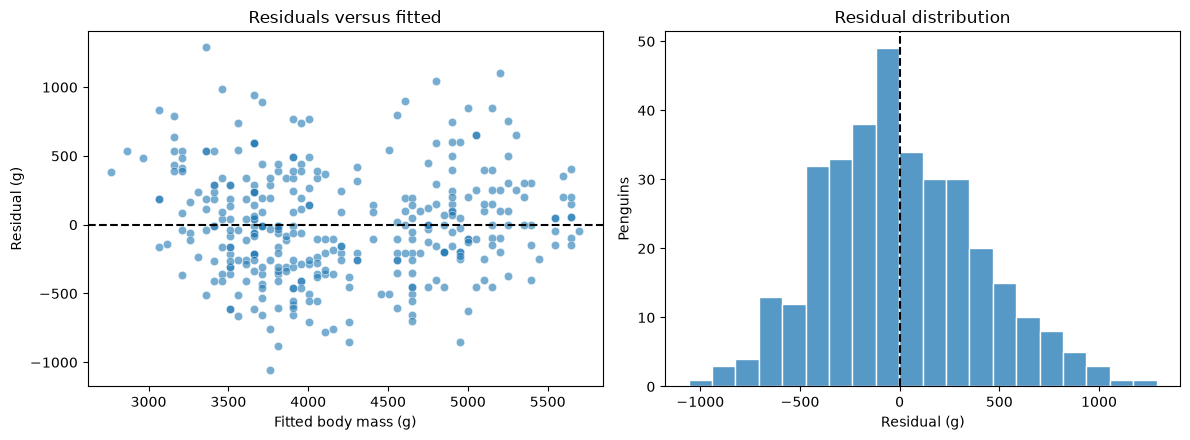

In [11]:
diagnostics = relationship_data.assign(
    fitted_body_mass_g=mass_model.fittedvalues, residual_g=mass_model.resid
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(
    data=diagnostics, x="fitted_body_mass_g", y="residual_g", alpha=0.6, ax=axes[0]
)
axes[0].axhline(0, color="black", ls="--")
axes[0].set(
    title="Residuals versus fitted",
    xlabel="Fitted body mass (g)",
    ylabel="Residual (g)",
)
sns.histplot(data=diagnostics, x="residual_g", bins=20, edgecolor="white", ax=axes[1])
axes[1].axvline(0, color="black", ls="--")
axes[1].set(title="Residual distribution", xlabel="Residual (g)", ylabel="Penguins")
fig.tight_layout()
plt.show()

**Question 8:** Look for curvature, changing spread, and unusual residuals. What limitations do the plots suggest?

**Answer:** The residuals are mostly centered around zero, but there are some large unusual residuals and the spread is not perfectly even. This suggests the linear model is useful, but it does not explain all of the variation.

## Check your work: residual signs
- Above the fitted line means a positive residual.
- Residual-versus-fitted uses a horizontal zero reference.
- A residual plot shows what the model leaves unexplained.

## VI. A pooled line can hide groups

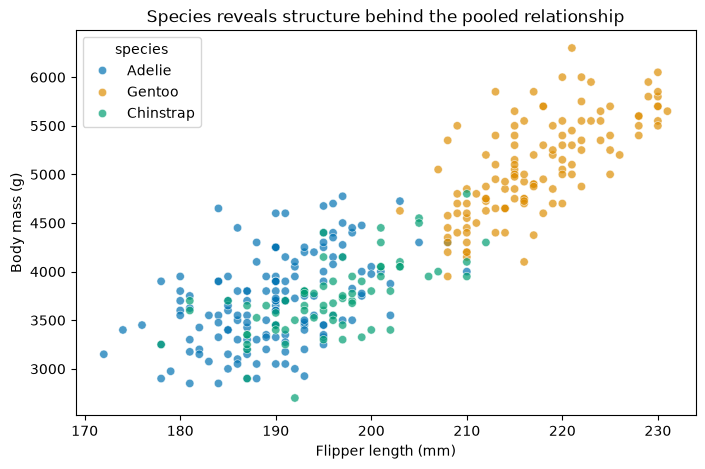

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=relationship_data,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette="colorblind",
    alpha=0.7,
    ax=ax,
)
ax.set(
    title="Species reveals structure behind the pooled relationship",
    xlabel="Flipper length (mm)",
    ylabel="Body mass (g)",
)
plt.show()

**Question 9:** What group structure appears, and why does it make the pooled model incomplete?

**Answer:** The graph shows clear groups by species. Gentoo penguins are generally heavier and have longer flippers, while Adelie and Chinstrap are smaller and overlap more. This makes the pooled model incomplete because species affects the relationship too.

## VII. Critique and substantial practice
**Question 10:** Diagnose a graph with opaque oversized points, missing units, hidden species, and the title “Long flippers make penguins heavy.” Explain at least four revisions.

**Answer:** I would make the points smaller and transparent, add units to both axes, show species with color, and use a clearer title. I would also change the title so it describes an association instead of claiming that long flippers cause higher body mass.

**Question 11:** Complete a new explanatory model using one pair: `bill_length_mm → flipper_length_mm`, `bill_depth_mm → body_mass_g`, or `bill_length_mm → body_mass_g`.

Your work must prepare complete rows plus species; create a scatterplot; fit OLS; interpret slope, interval, p-value, and R-squared; plot mean uncertainty; create residual-versus-fitted and residual-distribution plots; inspect species structure; and conclude with evidence, a limitation, and no causal claim.

**Your question:** How is bill length related to body mass in these recorded penguins?

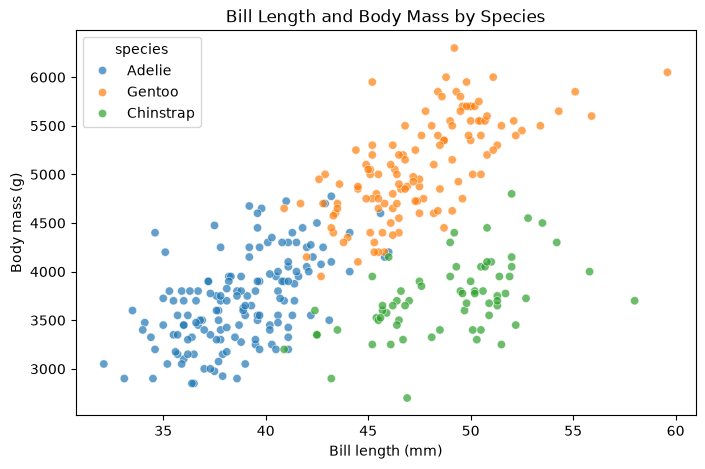

Intercept         362.306722
bill_length_mm     87.415277
dtype: float64
                         0           1
Intercept      -195.023642  919.637085
bill_length_mm   74.822791  100.007763
p-value: 3.8082828420188258e-34
R-squared: 0.3541557031421868


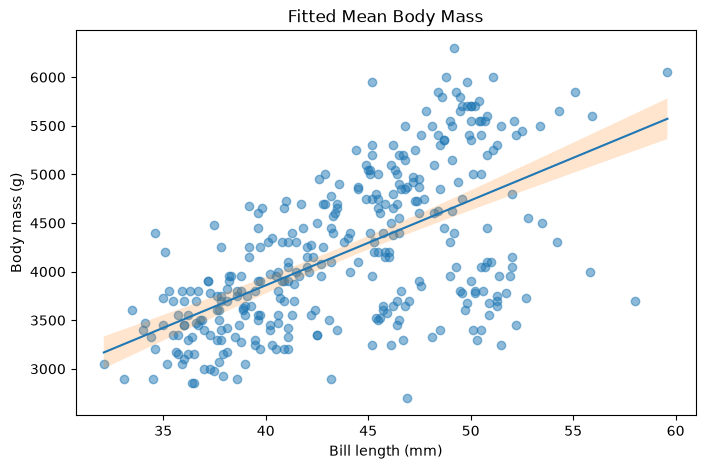

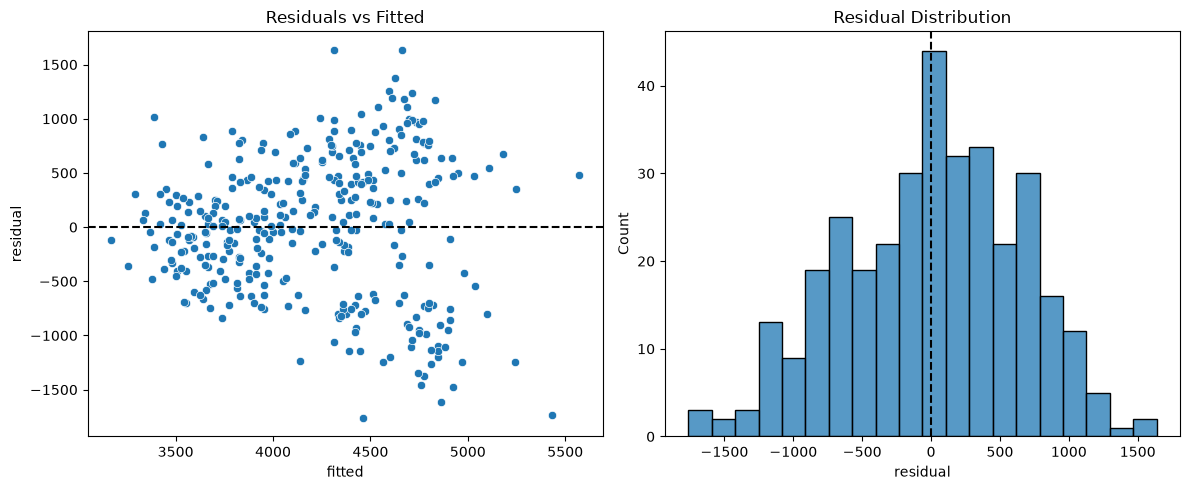

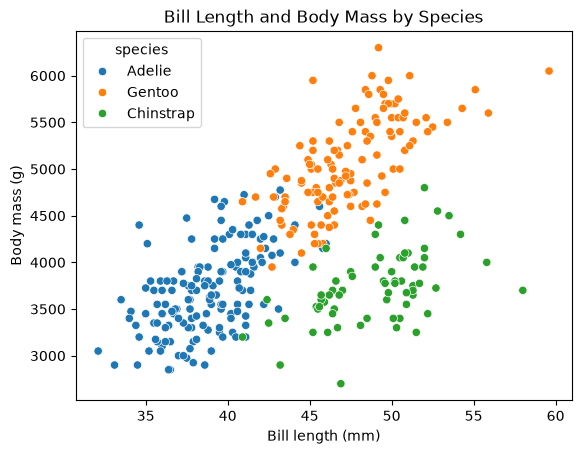

In [13]:
# Prepare complete rows
bill_data = (
    penguins[["bill_length_mm", "body_mass_g", "species"]]
    .dropna()
)

# Scatterplot
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=bill_data,
    x="bill_length_mm",
    y="body_mass_g",
    hue="species",
    alpha=.7,
    ax=ax
)

ax.set_title("Bill Length and Body Mass by Species")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Body mass (g)")
plt.show()

# Fit OLS model
bill_model = smf.ols(
    "body_mass_g ~ bill_length_mm",
    data=bill_data
).fit()

print(bill_model.params)
print(bill_model.conf_int())
print("p-value:", bill_model.pvalues["bill_length_mm"])
print("R-squared:", bill_model.rsquared)

# Mean uncertainty
grid = pd.DataFrame({
    "bill_length_mm": np.linspace(
        bill_data["bill_length_mm"].min(),
        bill_data["bill_length_mm"].max(),
        100
    )
})

summary = bill_model.get_prediction(grid).summary_frame()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    bill_data["bill_length_mm"],
    bill_data["body_mass_g"],
    alpha=.5
)

ax.plot(grid["bill_length_mm"], summary["mean"])
ax.fill_between(
    grid["bill_length_mm"],
    summary["mean_ci_lower"],
    summary["mean_ci_upper"],
    alpha=.2
)

ax.set_title("Fitted Mean Body Mass")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Body mass (g)")
plt.show()

# Residual plots
diagnostics = bill_data.assign(
    fitted=bill_model.fittedvalues,
    residual=bill_model.resid
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=diagnostics,
    x="fitted",
    y="residual",
    ax=axes[0]
)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Residuals vs Fitted")

sns.histplot(
    data=diagnostics,
    x="residual",
    bins=20,
    ax=axes[1]
)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

# Check species structure
sns.scatterplot(
    data=bill_data,
    x="bill_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.title("Bill Length and Body Mass by Species")
plt.xlabel("Bill length (mm)")
plt.ylabel("Body mass (g)")
plt.show()

## Submission check
- Complete Questions 1-11 and add your name/date.
- Restart and run all cells; inspect labels, units, intervals, and residual reference lines.
- Export to HTML, open it, and submit the completed HTML as directed in Canvas.